# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Global parameters
a, b = 2.0, 2.5    # interval za bisekcijo
x0, x1 = 2.0, 2.5  # zacetna priblizka
tol_list = [1e-6, 1e-12]
max_iter = 100

# Funkcije

In [2]:
# Simbolni zapis f(x) in odvod
x = sp.symbols("x", real=True)
f_sym = x - 2 * sp.sin(x) - sp.Rational(1, 2)
df_sym = sp.diff(f_sym, x)

# Numericni funkciji iz simbolnih izrazov
f = sp.lambdify(x, f_sym, "numpy")
df = sp.lambdify(x, df_sym, "numpy")

In [3]:
def bisekcija(f, a, b, tol=1e-12, max_iter=100):
    if f(a) * f(b) > 0:
        raise ValueError("Funkcija nima nasprotnih predznakov na robovih!")
    errs = []
    for k in range(max_iter):
        c = 0.5 * (a + b)
        fc = f(c)
        errs.append(abs(fc))
        if abs(fc) < tol or 0.5 * (b - a) < tol:
            return c, k + 1, errs
        if f(a) * fc < 0:
            b = c
        else:
            a = c
    return c, max_iter, errs

def newton_raphson(f, df, x0, tol=1e-12, max_iter=100):
    x = x0
    errs = []
    for k in range(max_iter):
        fx = f(x)
        errs.append(abs(fx))
        if abs(fx) < tol:
            return x, k + 1, errs
        dfx = df(x)
        if abs(dfx) < 1e-14:
            raise ZeroDivisionError("Odvod f'(x) je blizu nicli!")
        x = x - fx / dfx
    return x, max_iter, errs

def sekantna(f, x0, x1, tol=1e-12, max_iter=100):
    f0, f1 = f(x0), f(x1)
    errs = []
    for k in range(max_iter):
        errs.append(abs(f1))
        if abs(f1) < tol:
            return x1, k + 1, errs
        if abs(f1 - f0) < 1e-300:
            raise ZeroDivisionError("f(x_k) - f(x_{k-1}) je enako nic!")
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        x0, f0 = x1, f1
        x1, f1 = x2, f(x2)
    return x1, max_iter, errs

# Testno območje

In [11]:
# Pripravljalna naloga
display(sp.Eq(sp.Symbol("f'(x)"), df_sym))

for xi in (a, b):
    val = f_sym.subs(x, xi).evalf()
    print(f"f({xi}) = {float(val):+.6f}  (predznak: {'+' if val > 0 else '-'})")
print("Pogoj za bisekcijo f(a)*f(b) < 0:", f(a) * f(b) < 0)

Eq(f'(x), 1 - 2*cos(x))

f(2.0) = -0.318595  (predznak: -)
f(2.5) = +0.803056  (predznak: +)
Pogoj za bisekcijo f(a)*f(b) < 0: True


In [18]:
# Referencna nicla
x_ref = sp.nsolve(f_sym, x, 2.2, prec=30)
print(f"x_ref = {x_ref:.4f}")

x_ref = 2.1613


# Naloga 2

In [19]:
metode = {
    "Bisekcija": lambda tol: bisekcija(f, a, b, tol, max_iter),
    "Newton-Raphson": lambda tol: newton_raphson(f, df, x0, tol, max_iter),
    "Sekantna": lambda tol: sekantna(f, x0, x1, tol, max_iter),
}

rezultati = {}  # (ime, tol) -> (x*, st. korakov, napake)
for tol in tol_list:
    print(f"--- tol = {tol:.0e} ---")
    for ime, metoda in metode.items():
        rezultati[(ime, tol)] = metoda(tol)
        x_star, n_it, _ = rezultati[(ime, tol)]
        print(f"{ime:15s}: x* = {x_star:.12f}, iteracij = {n_it:2d}, |x* - x_ref| = {abs(x_star - float(x_ref)):.1e}")

--- tol = 1e-06 ---
Bisekcija      : x* = 2.161310195923, iteracij = 18, |x* - x_ref| = 4.0e-07
Newton-Raphson : x* = 2.161309794934, iteracij =  4, |x* - x_ref| = 1.5e-09
Sekantna       : x* = 2.161309779894, iteracij =  5, |x* - x_ref| = 1.4e-08
--- tol = 1e-12 ---
Bisekcija      : x* = 2.161309793465, iteracij = 39, |x* - x_ref| = 3.7e-13
Newton-Raphson : x* = 2.161309793465, iteracij =  5, |x* - x_ref| = 0.0e+00
Sekantna       : x* = 2.161309793465, iteracij =  6, |x* - x_ref| = 8.7e-14


# Naloga 3 - Slika 1

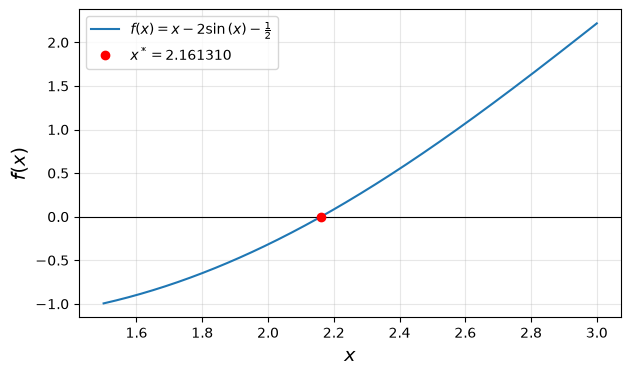

In [20]:
x_star = rezultati[("Newton-Raphson", 1e-12)][0]
xs = np.linspace(1.5, 3.0, 400)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.plot(xs, f(xs), label=f"$f(x) = {sp.latex(f_sym)}$")
ax.axhline(0.0, color="black", linewidth=0.8)
ax.plot(x_star, f(x_star), "o", color="red", label=f"$x^* = {x_star:.6f}$")
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$f(x)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Naloga 3 - Slika 2

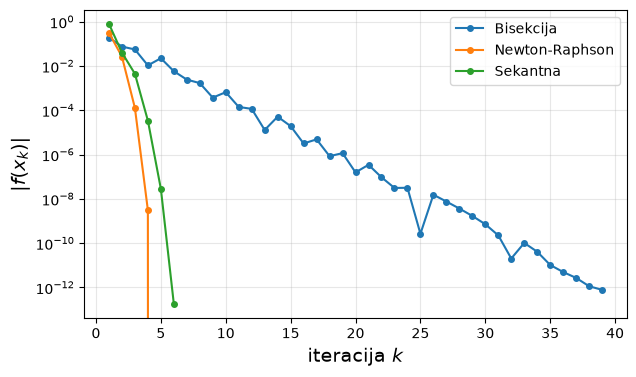

In [21]:
tol = 1e-12

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for ime in metode:
    napake = rezultati[(ime, tol)][2]
    ax.plot(range(1, len(napake) + 1), napake, "o-", markersize=4, label=ime)
ax.set_yscale("log")
ax.set_xlabel("iteracija $k$", fontsize=14)
ax.set_ylabel(r"$|f(x_k)|$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()

# Razmislek 1

In [22]:
# Tocke, kjer je f'(x) = 0 (na [0, 2pi])
ekstremi = sp.solveset(df_sym, x, sp.Interval(0, 2 * sp.pi))
display(ekstremi)

# Newton z zacetkom tik ob ekstremu x = pi/3
x_e = float(sp.pi / 3)
for dx in (1e-2, 1e-4):
    x_1 = x_e + dx - f(x_e + dx) / df(x_e + dx)
    print(f"x0 = pi/3 + {dx:.0e}: f'(x0) = {df(x_e + dx):+.1e}, x1 = {x_1:+.3e}")

{pi/3, 5*pi/3}

x0 = pi/3 + 1e-02: f'(x0) = +1.7e-02, x1 = +6.926e+01
x0 = pi/3 + 1e-04: f'(x0) = +1.7e-04, x1 = +6.842e+03


# Razmislek 2

In [23]:
# Bisekcija: (b - a) / 2^N < tol  =>  N >= log2((b - a) / tol)
eps, L = sp.symbols("varepsilon L", positive=True)
N_sym = sp.log(L / eps, 2)
display(sp.Eq(sp.Symbol("N_min"), N_sym))

for tol in tol_list:
    N = int(sp.ceiling(N_sym.subs({L: b - a, eps: tol})))
    print(f"tol = {tol:.0e}: N_min = {N}, bisekcija = {rezultati[('Bisekcija', tol)][1]}")

Eq(N_min, log(L/varepsilon)/log(2))

tol = 1e-06: N_min = 19, bisekcija = 18
tol = 1e-12: N_min = 39, bisekcija = 39
